In [1]:
import pandas as pd
import numpy as np 
from matplotlib import pyplot as plt

In [2]:
url = 'https://raw.githubusercontent.com/codebasics/deep-learning-keras-tf-tutorial/refs/heads/master/8_sgd_vs_gd/homeprices_banglore.csv'
df = pd.read_csv(url)
df.sample(5)

,area,bedrooms,price
9,3700,5,167.0
14,2250,3,101.0
12,1000,2,38.0
10,1800,3,82.0
13,1100,2,40.0


### Scaling the features

In [3]:
x_values = df.drop('price',axis='columns')
y_values = df['price'].values.reshape(df.shape[0],1)

In [4]:
x_values

,area,bedrooms
0,1056,2
1,2600,4
2,1440,3
3,1521,3
4,1200,2
5,1170,2
6,2732,4
7,3300,4
8,1310,3
9,3700,5


In [5]:
y_values

array([[ 39.07],
       [120.  ],
       [ 62.  ],
       [ 75.  ],
       [ 51.  ],
       [ 38.  ],
       [135.  ],
       [155.  ],
       [ 50.  ],
       [167.  ],
       [ 82.  ],
       [140.  ],
       [ 38.  ],
       [ 40.  ],
       [101.  ],
       [ 42.  ],
       [ 48.  ],
       [ 60.  ],
       [102.  ],
       [ 32.  ]])

In [6]:
from sklearn import preprocessing
sx = preprocessing.MinMaxScaler()
sy = preprocessing.MinMaxScaler()

scaled_X = sx.fit_transform(x_values)
scaled_y = sy.fit_transform(y_values)

In [7]:
scaled_X

array([[0.08827586, 0.25      ],
       [0.62068966, 0.75      ],
       [0.22068966, 0.5       ],
       [0.24862069, 0.5       ],
       [0.13793103, 0.25      ],
       [0.12758621, 0.25      ],
       [0.6662069 , 0.75      ],
       [0.86206897, 0.75      ],
       [0.17586207, 0.5       ],
       [1.        , 1.        ],
       [0.34482759, 0.5       ],
       [0.68448276, 0.75      ],
       [0.06896552, 0.25      ],
       [0.10344828, 0.25      ],
       [0.5       , 0.5       ],
       [0.12931034, 0.25      ],
       [0.13103448, 0.5       ],
       [0.25517241, 0.5       ],
       [0.67931034, 0.5       ],
       [0.        , 0.        ]])

In [8]:
scaled_y

array([[0.05237037],
       [0.65185185],
       [0.22222222],
       [0.31851852],
       [0.14074074],
       [0.04444444],
       [0.76296296],
       [0.91111111],
       [0.13333333],
       [1.        ],
       [0.37037037],
       [0.8       ],
       [0.04444444],
       [0.05925926],
       [0.51111111],
       [0.07407407],
       [0.11851852],
       [0.20740741],
       [0.51851852],
       [0.        ]])

In [11]:
scaled_y.reshape(20,)

array([0.05237037, 0.65185185, 0.22222222, 0.31851852, 0.14074074,
       0.04444444, 0.76296296, 0.91111111, 0.13333333, 1.        ,
       0.37037037, 0.8       , 0.04444444, 0.05925926, 0.51111111,
       0.07407407, 0.11851852, 0.20740741, 0.51851852, 0.        ])

In [14]:
scaled_X.shape

(20, 2)

In [15]:
scaled_X.shape[1]

2

In [16]:
w = np.ones(shape=(2))
w

array([1., 1.])

In [20]:
scaled_X

array([[0.08827586, 0.25      ],
       [0.62068966, 0.75      ],
       [0.22068966, 0.5       ],
       [0.24862069, 0.5       ],
       [0.13793103, 0.25      ],
       [0.12758621, 0.25      ],
       [0.6662069 , 0.75      ],
       [0.86206897, 0.75      ],
       [0.17586207, 0.5       ],
       [1.        , 1.        ],
       [0.34482759, 0.5       ],
       [0.68448276, 0.75      ],
       [0.06896552, 0.25      ],
       [0.10344828, 0.25      ],
       [0.5       , 0.5       ],
       [0.12931034, 0.25      ],
       [0.13103448, 0.5       ],
       [0.25517241, 0.5       ],
       [0.67931034, 0.5       ],
       [0.        , 0.        ]])

In [21]:
scaled_X.T

array([[0.08827586, 0.62068966, 0.22068966, 0.24862069, 0.13793103,
        0.12758621, 0.6662069 , 0.86206897, 0.17586207, 1.        ,
        0.34482759, 0.68448276, 0.06896552, 0.10344828, 0.5       ,
        0.12931034, 0.13103448, 0.25517241, 0.67931034, 0.        ],
       [0.25      , 0.75      , 0.5       , 0.5       , 0.25      ,
        0.25      , 0.75      , 0.75      , 0.5       , 1.        ,
        0.5       , 0.75      , 0.25      , 0.25      , 0.5       ,
        0.25      , 0.5       , 0.5       , 0.5       , 0.        ]])

In [22]:
np.dot(w,scaled_X.T)

array([0.33827586, 1.37068966, 0.72068966, 0.74862069, 0.38793103,
       0.37758621, 1.4162069 , 1.61206897, 0.67586207, 2.        ,
       0.84482759, 1.43448276, 0.31896552, 0.35344828, 1.        ,
       0.37931034, 0.63103448, 0.75517241, 1.17931034, 0.        ])

### Batch gradient descent

In [23]:
def batch_gradient_descent(X, y_true, epochs, learning_rate = 0.01):

    number_of_features = X.shape[1]
    
    # Two features: area and bedrooms.
    w = np.ones(shape=(number_of_features)) 
    b = 0
    total_samples = X.shape[0] 

    cost_list = []
    epoch_list = []

    for i in range(epochs):        
        y_predicted = np.dot(w, X.T) + b

        w_grad = -(2/total_samples)*(X.T.dot(y_true-y_predicted))
        b_grad = -(2/total_samples)*np.sum(y_true-y_predicted)

        w = w - learning_rate * w_grad
        b = b - learning_rate * b_grad

        cost = np.mean(np.square(y_true-y_predicted)) 

        if i%10==0:
            cost_list.append(cost)
            epoch_list.append(i)

    return w, b, cost, cost_list, epoch_list

w, b, cost, cost_list, epoch_list = batch_gradient_descent(scaled_X,scaled_y.reshape(scaled_y.shape[0],),500)
w, b, cost

(array([0.70712464, 0.67456527]), -0.23034857438407427, 0.0068641890429808105)

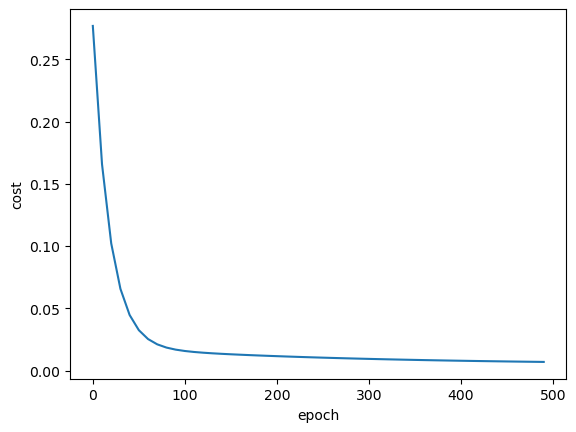

In [24]:
plt.xlabel("epoch")
plt.ylabel("cost")
plt.plot(epoch_list,cost_list)

In [25]:
w

array([0.70712464, 0.67456527])

In [26]:
sy.inverse_transform([[1]])[0][0]

166.99999999999997

In [27]:
def predict(area,bedrooms,w,b):
    scaled_X = sx.transform([[area, bedrooms]])[0]
    scaled_price = w[0] * scaled_X[0] + w[1] * scaled_X[1] + b
    return sy.inverse_transform([[scaled_price]])[0][0]

predict(2600,4,w,b)

128.45484403267596

### Stochastic gradient descent

In [29]:
import random
random_index = random.randint(0,20) 
random_index

12

In [30]:
sample_x = scaled_X[random_index]
sample_y = scaled_y[random_index]

In [31]:
sample_x

array([0.06896552, 0.25      ])

In [33]:
scaled_X

array([[0.08827586, 0.25      ],
       [0.62068966, 0.75      ],
       [0.22068966, 0.5       ],
       [0.24862069, 0.5       ],
       [0.13793103, 0.25      ],
       [0.12758621, 0.25      ],
       [0.6662069 , 0.75      ],
       [0.86206897, 0.75      ],
       [0.17586207, 0.5       ],
       [1.        , 1.        ],
       [0.34482759, 0.5       ],
       [0.68448276, 0.75      ],
       [0.06896552, 0.25      ],
       [0.10344828, 0.25      ],
       [0.5       , 0.5       ],
       [0.12931034, 0.25      ],
       [0.13103448, 0.5       ],
       [0.25517241, 0.5       ],
       [0.67931034, 0.5       ],
       [0.        , 0.        ]])

In [34]:
scaled_X.shape

(20, 2)

In [41]:
scaled_X

array([[0.08827586, 0.25      ],
       [0.62068966, 0.75      ],
       [0.22068966, 0.5       ],
       [0.24862069, 0.5       ],
       [0.13793103, 0.25      ],
       [0.12758621, 0.25      ],
       [0.6662069 , 0.75      ],
       [0.86206897, 0.75      ],
       [0.17586207, 0.5       ],
       [1.        , 1.        ],
       [0.34482759, 0.5       ],
       [0.68448276, 0.75      ],
       [0.06896552, 0.25      ],
       [0.10344828, 0.25      ],
       [0.5       , 0.5       ],
       [0.12931034, 0.25      ],
       [0.13103448, 0.5       ],
       [0.25517241, 0.5       ],
       [0.67931034, 0.5       ],
       [0.        , 0.        ]])

In [36]:
scaled_X[18]

array([0.67931034, 0.5       ])

In [40]:
scaled_y

array([[0.05237037],
       [0.65185185],
       [0.22222222],
       [0.31851852],
       [0.14074074],
       [0.04444444],
       [0.76296296],
       [0.91111111],
       [0.13333333],
       [1.        ],
       [0.37037037],
       [0.8       ],
       [0.04444444],
       [0.05925926],
       [0.51111111],
       [0.07407407],
       [0.11851852],
       [0.20740741],
       [0.51851852],
       [0.        ]])

In [39]:
scaled_y[18]

array([0.51851852])

In [43]:
def stochastic_gradient_descent(X, y_true, epochs, learning_rate = 0.01):

    number_of_features = X.shape[1]
    
    # Three features: area, bedrooms and age.
    w = np.ones(shape=(number_of_features)) 
    b = 0
    total_samples = X.shape[0]

    cost_list = []
    epoch_list = []

    for i in range(epochs):    
        random_index = random.randint(0,total_samples-1) 
        sample_x = X[random_index]
        sample_y = y_true[random_index]

        y_predicted = np.dot(w, sample_x.T) + b

        w_grad = -(2/total_samples)*(sample_x.T.dot(sample_y-y_predicted))
        b_grad = -(2/total_samples)*(sample_y-y_predicted)

        w = w - learning_rate * w_grad
        b = b - learning_rate * b_grad

        cost = np.square(sample_y-y_predicted)

        if i%100==0: 
            cost_list.append(cost)
            epoch_list.append(i)

    return w, b, cost, cost_list, epoch_list

w_sgd, b_sgd, cost_sgd, cost_list_sgd, epoch_list_sgd = stochastic_gradient_descent(scaled_X,scaled_y.reshape(scaled_y.shape[0],),10000)
w_sgd, b_sgd, cost_sgd

(array([0.7109631 , 0.67707103]), -0.2351903273323578, 0.023502029595641745)

In [45]:
w , b , cost

(array([0.70712464, 0.67456527]), -0.23034857438407427, 0.0068641890429808105)

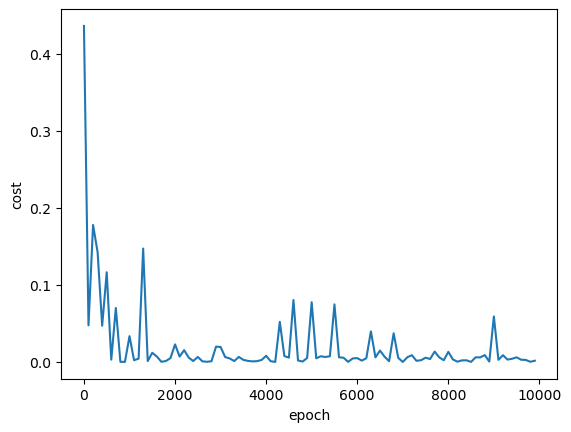

In [46]:
plt.xlabel("epoch")
plt.ylabel("cost")
plt.plot(epoch_list_sgd,cost_list_sgd)

In [47]:
predict(2600,4,w_sgd, b_sgd)

128.37655248938154

### Minibatch gradient descent

In [49]:
np.random.permutation(20)

array([15,  8,  3, 18, 16,  9,  0,  7, 17,  4,  2, 10, 19, 12, 14, 13,  1,
       11,  6,  5])

In [66]:
random_indices = np.random.permutation(20)
random_indices

array([ 4, 17,  5,  8,  6,  2, 18, 19, 15,  1,  3, 16, 12, 14, 11,  7,  0,
        9, 10, 13])

In [67]:
X_tmp = scaled_X[random_indices]
y_tmp = scaled_y[random_indices]

In [68]:
X_tmp

array([[0.13793103, 0.25      ],
       [0.25517241, 0.5       ],
       [0.12758621, 0.25      ],
       [0.17586207, 0.5       ],
       [0.6662069 , 0.75      ],
       [0.22068966, 0.5       ],
       [0.67931034, 0.5       ],
       [0.        , 0.        ],
       [0.12931034, 0.25      ],
       [0.62068966, 0.75      ],
       [0.24862069, 0.5       ],
       [0.13103448, 0.5       ],
       [0.06896552, 0.25      ],
       [0.5       , 0.5       ],
       [0.68448276, 0.75      ],
       [0.86206897, 0.75      ],
       [0.08827586, 0.25      ],
       [1.        , 1.        ],
       [0.34482759, 0.5       ],
       [0.10344828, 0.25      ]])

In [69]:
y_tmp

array([[0.14074074],
       [0.20740741],
       [0.04444444],
       [0.13333333],
       [0.76296296],
       [0.22222222],
       [0.51851852],
       [0.        ],
       [0.07407407],
       [0.65185185],
       [0.31851852],
       [0.11851852],
       [0.04444444],
       [0.51111111],
       [0.8       ],
       [0.91111111],
       [0.05237037],
       [1.        ],
       [0.37037037],
       [0.05925926]])

In [70]:
batch_size = 5
for j in range(0,20,batch_size):
    Xj = X_tmp[j:j+batch_size]
    yj = y_tmp[j:j+batch_size]
    print(j)
    print(Xj)
    print(yj)
    print('\n')

0
[[0.13793103 0.25      ]
 [0.25517241 0.5       ]
 [0.12758621 0.25      ]
 [0.17586207 0.5       ]
 [0.6662069  0.75      ]]
[[0.14074074]
 [0.20740741]
 [0.04444444]
 [0.13333333]
 [0.76296296]]


5
[[0.22068966 0.5       ]
 [0.67931034 0.5       ]
 [0.         0.        ]
 [0.12931034 0.25      ]
 [0.62068966 0.75      ]]
[[0.22222222]
 [0.51851852]
 [0.        ]
 [0.07407407]
 [0.65185185]]


10
[[0.24862069 0.5       ]
 [0.13103448 0.5       ]
 [0.06896552 0.25      ]
 [0.5        0.5       ]
 [0.68448276 0.75      ]]
[[0.31851852]
 [0.11851852]
 [0.04444444]
 [0.51111111]
 [0.8       ]]


15
[[0.86206897 0.75      ]
 [0.08827586 0.25      ]
 [1.         1.        ]
 [0.34482759 0.5       ]
 [0.10344828 0.25      ]]
[[0.91111111]
 [0.05237037]
 [1.        ]
 [0.37037037]
 [0.05925926]]




In [73]:
def mini_batch_gradient_descent(X, y_true, epochs = 100, batch_size = 5, learning_rate = 0.01):

    number_of_features = X.shape[1]
    
    # Three features: area, bedrooms and age.
    w = np.ones(shape=(number_of_features)) 
    b = 0
    total_samples = X.shape[0] 

    if batch_size > total_samples: 
        batch_size = total_samples

    cost_list = []
    epoch_list = []

    num_batches = int(total_samples/batch_size)

    for i in range(epochs):    
        random_indices = np.random.permutation(total_samples)
        X_tmp = X[random_indices]
        y_tmp = y_true[random_indices]

        for j in range(0,total_samples,batch_size):
            Xj = X_tmp[j:j+batch_size]
            yj = y_tmp[j:j+batch_size]
            y_predicted = np.dot(w, Xj.T) + b

            w_grad = -(2/len(Xj))*(Xj.T.dot(yj-y_predicted))
            b_grad = -(2/len(Xj))*np.sum(yj-y_predicted)

            w = w - learning_rate * w_grad
            b = b - learning_rate * b_grad

            cost = np.mean(np.square(yj-y_predicted)) 

        if i%10==0:
            cost_list.append(cost)
            epoch_list.append(i)

    return w, b, cost, cost_list, epoch_list

w_mbgd, b_mbgd, cost_mbgd, cost_list_mbgd, epoch_list_mbgd = mini_batch_gradient_descent(
    scaled_X,
    scaled_y.reshape(scaled_y.shape[0],),
    epochs = 120,
    batch_size = 5
)
w_mbgd, b_mbgd, cost_mbgd

(array([0.71012192, 0.6782388 ]), -0.23338245339545066, 0.004311130417141448)

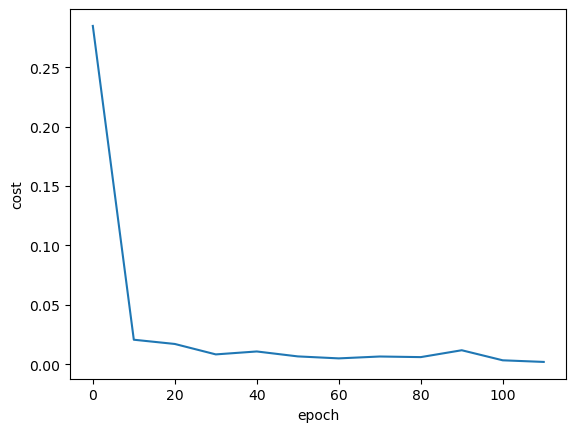

In [74]:
plt.xlabel("epoch")
plt.ylabel("cost")
plt.plot(epoch_list,cost_list)

In [76]:
predict(1000,2,w_mbgd,b_mbgd)

29.99540810379662

## Sources

Source: [Codebasics](https://github.com/codebasics/deep-learning-keras-tf-tutorial).

Source: [Stephen Welch, Neural Networks Demystified](https://github.com/stephencwelch/Neural-Networks-Demystified).